# Laboratorio de clasificación 3

|                |   |
:----------------|---|
| **Nombre**     | Juan Pablo Moran |
| **Fecha**      | 19/10/2026 |
| **Expediente** | 753760 |

Una regresión logística simple toma **P** predictores y usa una función no lineal para convertir la respuesta binaria **Y** en probabilidades entre $0$ y $1$.

La visualización de este escenario es puntos separados por una línea recta.

<center><img src="https://wirelesspi.com/wp-content/uploads/2022/08/figure-logistic-regression-decision-boundary-2-570x550.png"></center>

Para casos donde los datos no son linealmente separables usamos el truco del kernel para mapear los datos a un espacio de Hilbert.

Imagina un escenario donde tienes dos predictores $x_1, x_2$ y la salida de estos predictores se comporta de esta manera:

| **$x_1$** | **$x_2$** | Salida |
:-----------|-----------|--------|
| 0         | 0         | 0      |
| 0         | 1         | 1      |
| 1         | 0         | 1      |
| 1         | 1         | 0      |


Imagínalo como el interruptos de luz de un foco en una escalera. Se puede prender y apagar desde arriba y desde abajo.

<center><img src="https://www.researchgate.net/profile/Brian-Spears/publication/322048911/figure/fig4/AS:667820685807618@1536232267250/The-exclusive-or-XOR-function-is-a-nonlinear-function-that-returns-0-when-its-two.png"></center>

¿Cómo podemos separar estos datos usando sólo regresión logística? Sin importar cómo usemos una sola línea, nunca se van a poder separar todos los casos, por lo que tendríamos situaciones donde siempre habría error. 

Solución: ¿Por qué nos estamos limitando a una sola línea?

<center><img src="https://pabloinsente.github.io/assets/post-5/XOR-linear.png"></center>

La regresión logística sola es un método de aprendizaje estadístico convexo. Combinar dos regresiones logísticas para clasificar datos no linealmente separables convierte el problema a uno no convexo. ¿Por qué?

- Una regresion logistica sola tiene una funcion de costo (log-loss) convexa porque la salida es la sigmoide de una combinacion lineal de los parametros
- Al combinar dos regresiones logisticas, la salida de una entra como factor a la otra, entonces la salida final es una sigmoide de sigmoides
- Esa composicion ya no es convexa respecto a los parametros: aparecen varios minimos locales y zonas planas
- Ademas hay simetria: si intercambias las dos neuronas ocultas el modelo da exactamente lo mismo, asi que hay mas de un minimo con el mismo costo, lo cual no puede pasar en una funcion convexa

¿Qué significa que una función sea convexa?

- Una funcion es convexa si el segmento que une dos puntos cualesquiera de la grafica queda por encima (o sobre) la grafica
- En formula: f(t*a + (1-t)*b) <= t*f(a) + (1-t)*f(b) para todo t entre 0 y 1
- Graficamente tiene forma de "taza" y si tiene un minimo local, ese es el minimo global

¿Por qué nos importa que una función sea convexa o no? ¿Qué impacto tiene para los resultados?

- Si la funcion de costo es convexa, cualquier metodo de descenso de gradiente llega siempre al minimo global, sin importar desde donde empiece
- Los resultados son estables: correr el modelo varias veces da los mismos coeficientes
- Si no es convexa (como una red neuronal) el optimizador se puede quedar atorado en un minimo local
- El resultado depende de los pesos iniciales (por eso se fija `random_state`), puede cambiar entre corridas y hay que ajustar mas hiperparametros (tasa de aprendizaje, iteraciones, etc.)

## Ejercicio 1

Utilizaremos el clasificador `MLPClassifier` de la librería `sklearn`.

Entra a la documentación y describe cómo funciona este objeto (qué entradas necesita, qué salidas da, descripción de sus hiperparámetros).

**Que es**
- `MLPClassifier` es un perceptron multicapa: una red neuronal con capas ocultas que se entrena con backpropagation
- Cada neurona hace una combinacion lineal de sus entradas y le aplica una funcion de activacion; la ultima capa da la probabilidad de cada clase

**Entradas**
- `fit(X, y)`: X es la matriz de factores (n muestras x p factores, numericos) y y es la clase de cada muestra
- Es sensible a la escala, por eso se recomienda escalar los datos antes

**Salidas**
- `predict(X)`: la clase predicha
- `predict_proba(X)`: la probabilidad de cada clase
- `score(X, y)`: el accuracy
- Atributos: `coefs_` (pesos de cada capa), `intercepts_`, `loss_`, `loss_curve_`, `n_iter_`

**Hiperparametros principales**
- `hidden_layer_sizes`: numero de neuronas por capa oculta, ej. (100,) es una capa de 100 y (50, 20) son dos capas
- `activation`: funcion de activacion de las capas ocultas: "identity", "logistic", "tanh" o "relu" (default)
- `solver`: optimizador: "adam" (default), "sgd" o "lbfgs" (bueno para datasets chicos)
- `alpha`: fuerza de la regularizacion L2, mas alto = modelo mas simple (default 0.0001)
- `batch_size`: tamano de los lotes para sgd y adam
- `learning_rate_init`: tasa de aprendizaje inicial (default 0.001)
- `learning_rate`: si la tasa es constante o va bajando ("constant", "invscaling", "adaptive"), solo para sgd
- `max_iter`: numero maximo de iteraciones (epocas) (default 200)
- `early_stopping`: separa una parte de los datos para validar y se detiene si ya no mejora
- `random_state`: semilla para los pesos iniciales, para que el resultado sea reproducible

## Ejercicio 2

Utiliza el objeto de perceptrón multicapa para clasificar si un tumor es maligno o benigno con el dataset `Brain Tumor Dataset`. Utiliza un cross-validation de train-test de 70/30. Sigue todos los pasos de EDA y limpieza vistos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("brain_tumor_dataset.csv")
print(df.shape)
df.head()

(20000, 19)


,Patient_ID,Age,Gender,Tumor_Type,Tumor_Size,Location,Histology,Stage,Symptom_1,Symptom_2,Symptom_3,Radiation_Treatment,Surgery_Performed,Chemotherapy,Survival_Rate,Tumor_Growth_Rate,Family_History,MRI_Result,Follow_Up_Required
0,1,73,Male,Malignant,5.375612,Temporal,Astrocytoma,III,Vision Issues,Seizures,Seizures,No,No,No,51.312579,0.111876,No,Positive,Yes
1,2,26,Male,Benign,4.847098,Parietal,Glioblastoma,II,Headache,Headache,Nausea,Yes,Yes,Yes,46.373273,2.165736,Yes,Positive,Yes
2,3,31,Male,Benign,5.588391,Parietal,Meningioma,I,Vision Issues,Headache,Seizures,No,No,No,47.072221,1.884228,No,Negative,No
3,4,29,Male,Malignant,1.436600,Temporal,Medulloblastoma,IV,Vision Issues,Seizures,Headache,Yes,No,Yes,51.853634,1.283342,Yes,Negative,No
4,5,54,Female,Benign,2.417506,Parietal,Glioblastoma,I,Headache,Headache,Seizures,No,No,Yes,54.708987,2.069477,No,Positive,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Patient_ID           20000 non-null  int64  
 1   Age                  20000 non-null  int64  
 2   Gender               20000 non-null  str    
 3   Tumor_Type           20000 non-null  str    
 4   Tumor_Size           20000 non-null  float64
 5   Location             20000 non-null  str    
 6   Histology            20000 non-null  str    
 7   Stage                20000 non-null  str    
 8   Symptom_1            20000 non-null  str    
 9   Symptom_2            20000 non-null  str    
 10  Symptom_3            20000 non-null  str    
 11  Radiation_Treatment  20000 non-null  str    
 12  Surgery_Performed    20000 non-null  str    
 13  Chemotherapy         20000 non-null  str    
 14  Survival_Rate        20000 non-null  float64
 15  Tumor_Growth_Rate    20000 non-null  float64
 1

In [3]:
print(df.isnull().sum())
print(df.duplicated().sum())

Patient_ID             0
Age                    0
Gender                 0
Tumor_Type             0
Tumor_Size             0
Location               0
Histology              0
Stage                  0
Symptom_1              0
Symptom_2              0
Symptom_3              0
Radiation_Treatment    0
Surgery_Performed      0
Chemotherapy           0
Survival_Rate          0
Tumor_Growth_Rate      0
Family_History         0
MRI_Result             0
Follow_Up_Required     0
dtype: int64
0


In [4]:
df.describe()

,Patient_ID,Age,Tumor_Size,Survival_Rate,Tumor_Growth_Rate
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,49.433700,5.236552,70.131699,1.547701
std,5773.647028,17.389296,2.754359,17.270834,0.835995
min,1.000000,20.000000,0.500410,40.002386,0.100017
25%,5000.750000,34.000000,2.836686,55.224439,0.830433
50%,10000.500000,49.000000,5.200675,70.305066,1.541821
75%,15000.250000,65.000000,7.624299,85.043395,2.262484
max,20000.000000,79.000000,9.999420,99.998125,2.999835


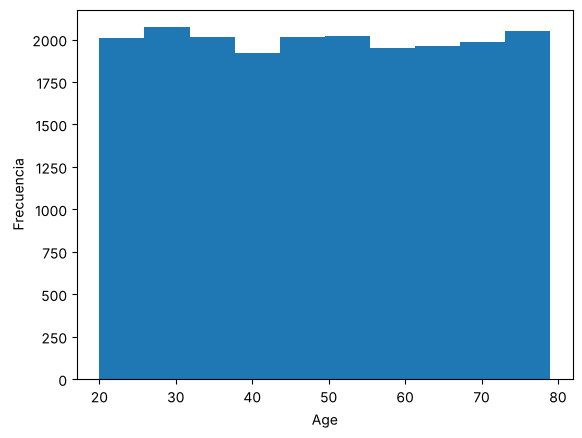

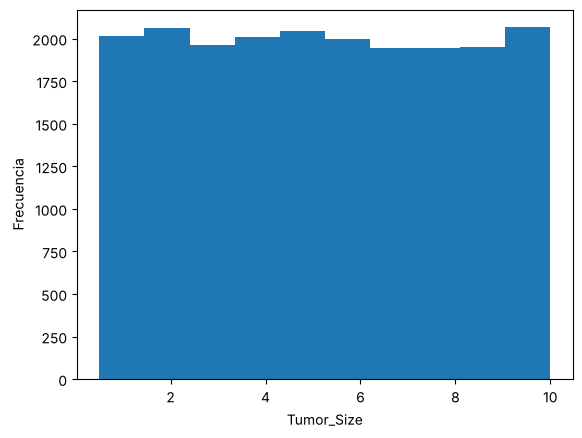

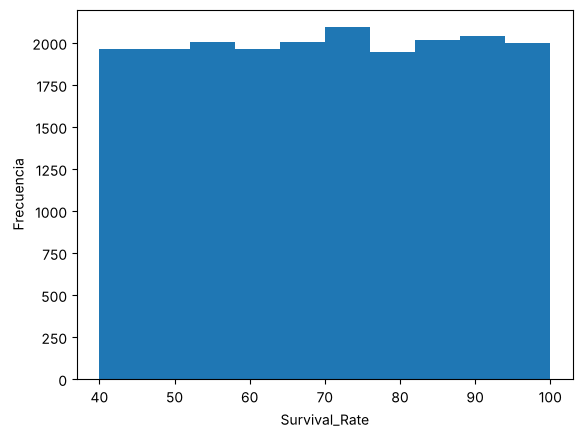

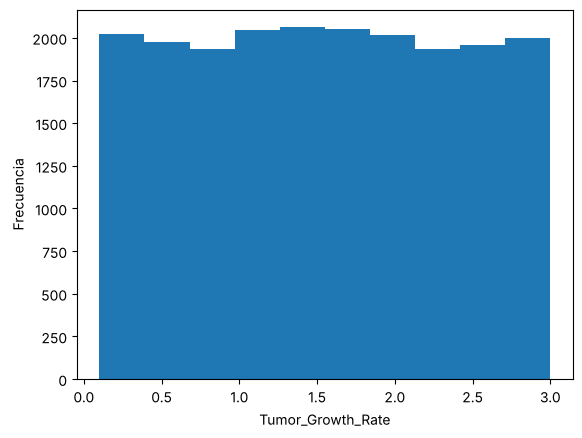

In [5]:
for col in ["Age", "Tumor_Size", "Survival_Rate", "Tumor_Growth_Rate"]:
    plt.figure()
    plt.hist(df[col])
    plt.xlabel(col)
    plt.ylabel("Frecuencia")

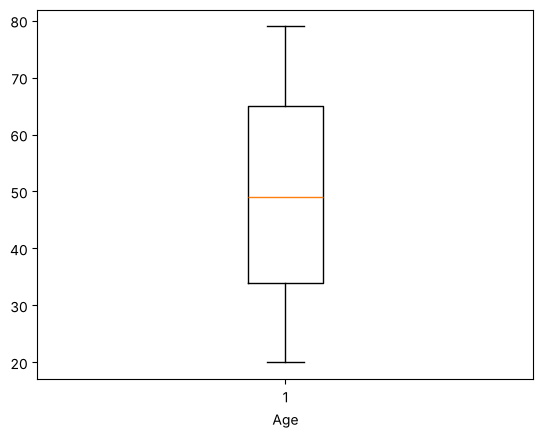

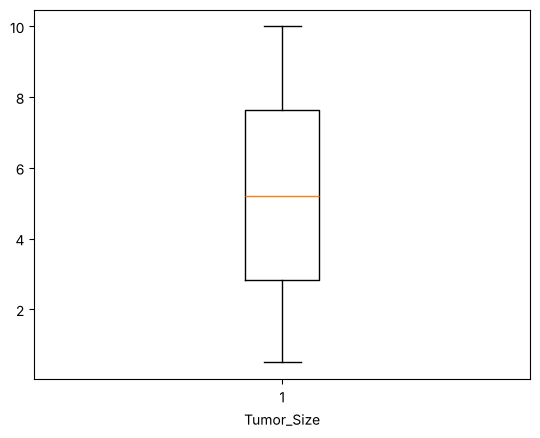

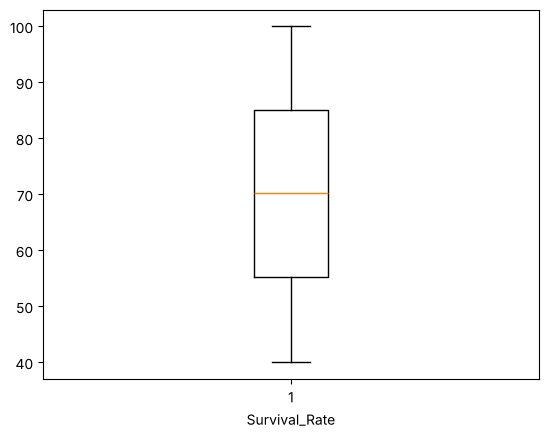

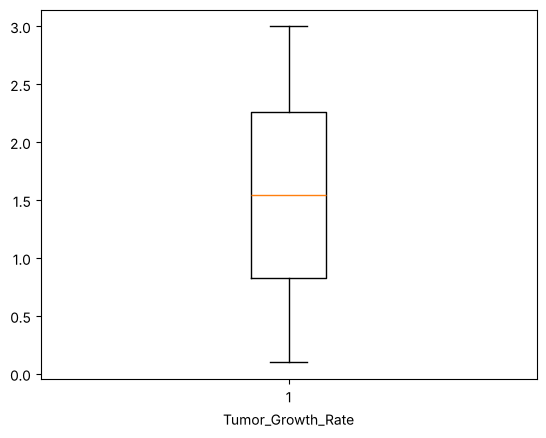

In [6]:
for col in ["Age", "Tumor_Size", "Survival_Rate", "Tumor_Growth_Rate"]:
    plt.figure()
    plt.boxplot(df[col])
    plt.xlabel(col)

In [7]:
categoricas = ["Gender", "Tumor_Type", "Location", "Histology", "Stage", "Symptom_1", "Symptom_2",
               "Symptom_3", "Radiation_Treatment", "Surgery_Performed", "Chemotherapy",
               "Family_History", "MRI_Result", "Follow_Up_Required"]
for col in categoricas:
    print(col, df[col].unique())

Gender <StringArray>
['Male', 'Female']
Length: 2, dtype: str
Tumor_Type <StringArray>
['Malignant', 'Benign']
Length: 2, dtype: str
Location <StringArray>
['Temporal', 'Parietal', 'Frontal', 'Occipital']
Length: 4, dtype: str
Histology <StringArray>
['Astrocytoma', 'Glioblastoma', 'Meningioma', 'Medulloblastoma']
Length: 4, dtype: str
Stage <StringArray>
['III', 'II', 'I', 'IV']
Length: 4, dtype: str
Symptom_1 <StringArray>
['Vision Issues', 'Headache', 'Seizures', 'Nausea']
Length: 4, dtype: str
Symptom_2 <StringArray>
['Seizures', 'Headache', 'Vision Issues', 'Nausea']
Length: 4, dtype: str
Symptom_3 <StringArray>
['Seizures', 'Nausea', 'Headache', 'Vision Issues']
Length: 4, dtype: str
Radiation_Treatment <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Surgery_Performed <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Chemotherapy <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Family_History <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MRI_Result <StringArray>
['Positive

Text(0, 0.5, 'Frecuencia')

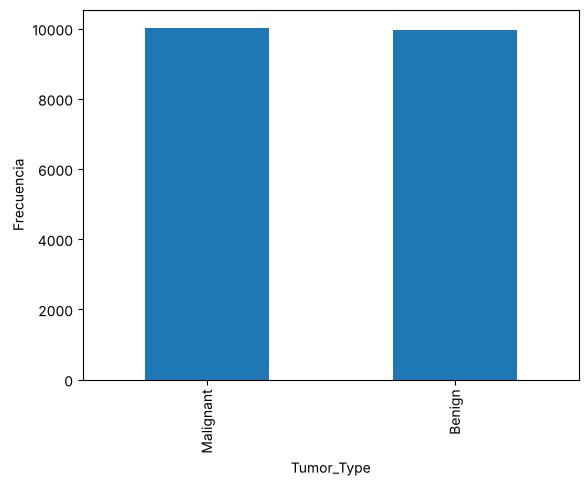

In [8]:
plt.figure()
df["Tumor_Type"].value_counts().plot(kind="bar")
plt.xlabel("Tumor_Type")
plt.ylabel("Frecuencia")

In [9]:
df.groupby("Tumor_Type")[["Age", "Tumor_Size", "Survival_Rate", "Tumor_Growth_Rate"]].mean()

,Age,Tumor_Size,Survival_Rate,Tumor_Growth_Rate
Tumor_Type,,,,
Benign,49.333701,5.276205,70.178522,1.548122
Malignant,49.533101,5.197136,70.085157,1.547283


- 20,000 pacientes y 19 columnas, sin nulos ni duplicados, y las categorias no tienen errores de escritura
- Las clases estan balanceadas (10,030 malignos y 9,970 benignos)
- No hay outliers en las variables numericas, se ven distribuidas casi uniformes
- Los promedios de las variables numericas son practicamente iguales entre benignos y malignos, asi que se espera que sea dificil predecir

In [10]:
df = df.drop_duplicates()
df = df.dropna()

df = df[["Age", "Gender", "Tumor_Type", "Tumor_Size", "Location", "Histology", "Stage", "Symptom_1",
         "Symptom_2", "Symptom_3", "Radiation_Treatment", "Surgery_Performed", "Chemotherapy",
         "Survival_Rate", "Tumor_Growth_Rate", "Family_History", "MRI_Result", "Follow_Up_Required"]]

df["Tumor_Type"] = df["Tumor_Type"].replace({"Malignant": 1, "Benign": 0})
df["Gender"] = df["Gender"].replace({"Male": 1, "Female": 0})
df["Stage"] = df["Stage"].replace({"I": 1, "II": 2, "III": 3, "IV": 4})
df["MRI_Result"] = df["MRI_Result"].replace({"Positive": 1, "Negative": 0})
for col in ["Radiation_Treatment", "Surgery_Performed", "Chemotherapy", "Family_History", "Follow_Up_Required"]:
    df[col] = df[col].replace({"Yes": 1, "No": 0})

for col in ["Location", "Histology", "Symptom_1", "Symptom_2", "Symptom_3"]:
    valores = df[col].unique()
    for v in valores[1:]:
        df[col + "_" + v] = (df[col] == v).astype(int)

columnas = list(df.columns)
for col in ["Location", "Histology", "Symptom_1", "Symptom_2", "Symptom_3"]:
    columnas.remove(col)
df = df[columnas]

df = df.astype(float)
print(df.shape)
df.head()

(20000, 28)


,Age,Gender,Tumor_Type,Tumor_Size,Stage,Radiation_Treatment,Surgery_Performed,Chemotherapy,Survival_Rate,Tumor_Growth_Rate,...,Histology_Medulloblastoma,Symptom_1_Headache,Symptom_1_Seizures,Symptom_1_Nausea,Symptom_2_Headache,Symptom_2_Vision Issues,Symptom_2_Nausea,Symptom_3_Nausea,Symptom_3_Headache,Symptom_3_Vision Issues
0,73.0,1.0,1.0,5.375612,3.0,0.0,0.0,0.0,51.312579,0.111876,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,26.0,1.0,0.0,4.847098,2.0,1.0,1.0,1.0,46.373273,2.165736,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,31.0,1.0,0.0,5.588391,1.0,0.0,0.0,0.0,47.072221,1.884228,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,29.0,1.0,1.0,1.436600,4.0,1.0,0.0,1.0,51.853634,1.283342,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,54.0,0.0,0.0,2.417506,1.0,0.0,0.0,1.0,54.708987,2.069477,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


- Se quita `Patient_ID` porque solo es un identificador
- Las variables Yes/No y el genero se pasan a 1 y 0, `Stage` a 1-4 porque tiene orden
- `Location`, `Histology` y los sintomas se pasan a variables dummy (una columna por categoria menos una)

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

columnas = list(df.columns)
columnas.remove("Tumor_Type")
X = df[columnas]
y = df["Tumor_Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(14000, 27) (6000, 27)


In [12]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

mlp = MLPClassifier(random_state=42, max_iter=500)
mlp.fit(X_train, y_train)
y_pred = mlp.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))
print("AUC:", roc_auc_score(y_test, mlp.predict_proba(X_test)[:, 1]))
confusion_matrix(y_test, y_pred)

              precision    recall  f1-score   support

      Benign       0.49      0.48      0.48      2962
   Malignant       0.50      0.50      0.50      3038

    accuracy                           0.49      6000
   macro avg       0.49      0.49      0.49      6000
weighted avg       0.49      0.49      0.49      6000

AUC: 0.4927808417261614


array([[1430, 1532],
       [1516, 1522]])

- El modelo tiene un desempeno de alrededor de 50% en todas las metricas, practicamente igual que adivinar al azar
- Esto concuerda con el EDA: ninguna variable cambia entre tumores benignos y malignos, el dataset no tiene informacion para separar las clases

¿Qué métrico crees que sea mejor para este ejercicio? Escoge los 3 métricos que crees más apropiados para esta predicción, argumenta en pro y en contra del top 3. Elige uno para optimizar (justifica tu respuesta).

**1. Recall (sensibilidad) de la clase maligno**
- Pro: mide cuantos tumores malignos detecta el modelo; un falso negativo (decir benigno a alguien con tumor maligno) es el peor error porque el paciente no recibe tratamiento
- Contra: se puede subir artificialmente diciendo "maligno" a todos, lo cual llena de falsos positivos

**2. F1-score**
- Pro: combina precision y recall en un solo numero, castiga al modelo si alguno de los dos es malo
- Contra: le da el mismo peso a falsos positivos y falsos negativos, y aqui no cuestan lo mismo

**3. AUC ROC**
- Pro: evalua el modelo en todos los umbrales, no depende de usar 0.5 para decidir
- Contra: no dice que tan bien funciona en el umbral que realmente se usa y es menos facil de explicar a un medico

**Metrica a optimizar: recall**
- En un problema medico es mucho mas grave no detectar un tumor maligno que mandar a un paciente sano a mas estudios
- Para no caer en predecir todo como maligno, se revisa tambien el F1 al comparar los modelos

## Ejercicio 3

Modifica los hiperparámetros para elevar el métrico elegido. Intenta con 10 sets de hiperparámetros distintos. Crea una tabla que muestre los resultados.

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

configuraciones = [
    ((100,), "relu", "adam", 0.0001, 0.001),
    ((50,), "relu", "adam", 0.0001, 0.001),
    ((100, 50), "relu", "adam", 0.0001, 0.001),
    ((100,), "tanh", "adam", 0.0001, 0.001),
    ((100,), "logistic", "adam", 0.0001, 0.001),
    ((100,), "relu", "adam", 0.01, 0.001),
    ((100,), "relu", "adam", 1.0, 0.001),
    ((100,), "relu", "sgd", 0.0001, 0.01),
    ((10,), "logistic", "lbfgs", 0.0001, 0.001),
    ((20, 10), "tanh", "adam", 0.1, 0.0001),
]

capas = []
activaciones = []
solvers = []
alphas = []
tasas = []
acc = []
prec = []
rec = []
f1 = []
auc = []

for c in configuraciones:
    mlp = MLPClassifier(hidden_layer_sizes=c[0], activation=c[1], solver=c[2], alpha=c[3],
                        learning_rate_init=c[4], max_iter=500, random_state=42)
    mlp.fit(X_train, y_train)
    y_pred = mlp.predict(X_test)

    capas.append(str(c[0]))
    activaciones.append(c[1])
    solvers.append(c[2])
    alphas.append(c[3])
    tasas.append(c[4])
    acc.append(accuracy_score(y_test, y_pred))
    prec.append(precision_score(y_test, y_pred))
    rec.append(recall_score(y_test, y_pred))
    f1.append(f1_score(y_test, y_pred))
    auc.append(roc_auc_score(y_test, mlp.predict_proba(X_test)[:, 1]))

resultados = pd.DataFrame({"capas": capas, "activation": activaciones, "solver": solvers,
                           "alpha": alphas, "learning_rate_init": tasas, "accuracy": acc,
                           "precision": prec, "recall": rec, "f1": f1, "AUC": auc})
resultados.index = range(1, 11)
resultados

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,capas,activation,solver,alpha,learning_rate_init,accuracy,precision,recall,f1,AUC
1,"(100,)",relu,adam,0.0001,0.0010,0.492000,0.498363,0.500987,0.499672,0.492781
2,"(50,)",relu,adam,0.0001,0.0010,0.490667,0.497117,0.510862,0.503896,0.488120
3,"(100, 50)",relu,adam,0.0001,0.0010,0.491333,0.497706,0.500000,0.498851,0.482723
4,"(100,)",tanh,adam,0.0001,0.0010,0.487167,0.493566,0.492429,0.492997,0.489128
5,"(100,)",logistic,adam,0.0001,0.0010,0.498667,0.508117,0.309085,0.384363,0.507251
6,"(100,)",relu,adam,0.0100,0.0010,0.490833,0.497223,0.500987,0.499098,0.492089
7,"(100,)",relu,adam,1.0000,0.0010,0.493333,0.499588,0.399605,0.444038,0.494136
8,"(100,)",relu,sgd,0.0001,0.0100,0.495500,0.501876,0.484200,0.492880,0.496133
9,"(10,)",logistic,lbfgs,0.0001,0.0010,0.506833,0.514002,0.477288,0.494965,0.505350
10,"(20, 10)",tanh,adam,0.1000,0.0001,0.503667,0.510295,0.489467,0.499664,0.503795


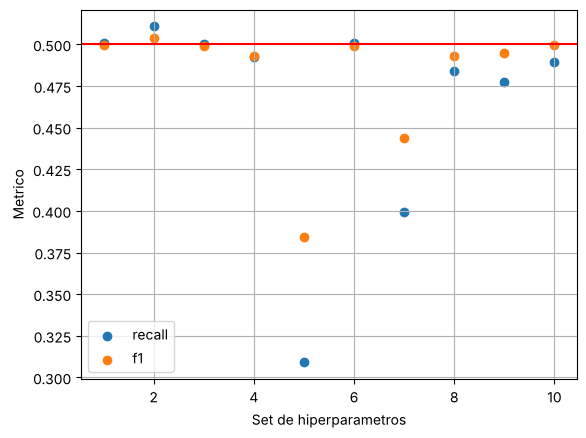

In [14]:
plt.figure()
plt.scatter(resultados.index, resultados["recall"], label="recall")
plt.scatter(resultados.index, resultados["f1"], label="f1")
plt.axhline(0.5, color="red")
plt.xlabel("Set de hiperparametros")
plt.ylabel("Metrico")
plt.legend()
plt.grid()

- Todos los sets quedan alrededor de 50% de accuracy y AUC, ningun set de hiperparametros mejora realmente el modelo
- El mejor recall lo tuvo el set 2 (una capa de 50 neuronas, relu): recall 0.511 y f1 0.504, por lo que es el que se elegiria
- Los sets 5 (activacion logistic) y 7 (alpha = 1) bajan mucho el recall (0.31 y 0.40) porque predicen benigno mas seguido
- Las diferencias entre sets son muy chicas y se explican por azar: como vimos en el EDA, las variables no tienen relacion con el tipo de tumor, asi que el problema son los datos, no los hiperparametros